In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [3]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


In [4]:
# Dataset paths
base_dir = r"data\Skin Lesions Classification"
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')


In [5]:
# Quick dataset check (run once)
for split_dir in [train_dir, test_dir]:
    classes = sorted([d for d in os.listdir(split_dir) if os.path.isdir(os.path.join(split_dir, d))])
    counts = {}
    for c in classes:
        cdir = os.path.join(split_dir, c)
        counts[c] = len([f for f in os.listdir(cdir) if os.path.isfile(os.path.join(cdir, f))])
    print(f"{os.path.basename(split_dir)} classes: {classes}")
    print(f"{os.path.basename(split_dir)} counts: {counts}")


train classes: ['benign', 'malignant']
train counts: {'benign': 1440, 'malignant': 1197}
test classes: ['benign', 'malignant']
test counts: {'benign': 361, 'malignant': 300}


In [6]:
# Image parameters
img_size = 224
batch_size = 16
num_classes = 2
num_epochs = 50
patience = 8


In [7]:
# Data augmentation and normalization
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(img_size),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


In [8]:
# Datasets
full_train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_size = int(0.2 * len(full_train_dataset))
train_size = len(full_train_dataset) - val_size
train_data, val_data = torch.utils.data.random_split(full_train_dataset, [train_size, val_size])

test_data = datasets.ImageFolder(test_dir, transform=val_test_transforms)

# Build a class-weighted sampler for the training split
train_labels = [full_train_dataset.targets[i] for i in train_data.indices]
class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts
sample_weights = [class_weights[label] for label in train_labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)


In [9]:
# Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, sampler=sampler)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [10]:
# Define model (transfer learning)
model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False

in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, num_classes)
model = model.to(device)


In [11]:
# Loss, optimizer, scheduler
class_weights_t = torch.tensor(class_weights, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)


In [12]:
# Training loop with early stopping (monitor val loss)
best_val_loss = float('inf')
counter = 0
train_acc_hist, val_acc_hist = [], []
train_loss_hist, val_loss_hist = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    train_acc_hist.append(train_acc.item())
    val_acc_hist.append(val_acc.item())
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'skin_lesions_model_mobilenetv3.pth')
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping.")
            break

# Load best model
model.load_state_dict(torch.load('skin_lesions_model_mobilenetv3.pth'))


Epoch 1/50, Train Acc: 0.7592, Val Acc: 0.7723, Val Loss: 0.4896
Epoch 2/50, Train Acc: 0.8213, Val Acc: 0.7894, Val Loss: 0.4578
Epoch 3/50, Train Acc: 0.8009, Val Acc: 0.8008, Val Loss: 0.4366
Epoch 4/50, Train Acc: 0.8095, Val Acc: 0.8121, Val Loss: 0.4104
Epoch 5/50, Train Acc: 0.8028, Val Acc: 0.7837, Val Loss: 0.4501
Epoch 6/50, Train Acc: 0.8085, Val Acc: 0.7989, Val Loss: 0.4503
Epoch 7/50, Train Acc: 0.8218, Val Acc: 0.8083, Val Loss: 0.4311
Epoch 8/50, Train Acc: 0.8043, Val Acc: 0.7894, Val Loss: 0.4384
Epoch 9/50, Train Acc: 0.8114, Val Acc: 0.7951, Val Loss: 0.4203
Epoch 10/50, Train Acc: 0.8128, Val Acc: 0.8292, Val Loss: 0.4030
Epoch 11/50, Train Acc: 0.8137, Val Acc: 0.7818, Val Loss: 0.4587
Epoch 12/50, Train Acc: 0.8156, Val Acc: 0.7894, Val Loss: 0.4289
Epoch 13/50, Train Acc: 0.8161, Val Acc: 0.8027, Val Loss: 0.4395
Epoch 14/50, Train Acc: 0.8114, Val Acc: 0.8292, Val Loss: 0.3967
Epoch 15/50, Train Acc: 0.8246, Val Acc: 0.8083, Val Loss: 0.4308
Epoch 16/50, Train 

<All keys matched successfully>

In [13]:
# Optional fine-tuning (unfreeze last block for a few more epochs)
for name, param in model.named_parameters():
    if name.startswith('layer4'):
        param.requires_grad = True

fine_tune_epochs = 10
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

for epoch in range(fine_tune_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    print(f"Fine-tune Epoch {epoch+1}/{fine_tune_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

# Save final fine-tuned model
torch.save(model.state_dict(), 'skin_lesions_model_mobilenetv3.pth')


Fine-tune Epoch 1/10, Train Acc: 0.8261, Val Acc: 0.8083, Val Loss: 0.4146
Fine-tune Epoch 2/10, Train Acc: 0.8142, Val Acc: 0.7970, Val Loss: 0.4074
Fine-tune Epoch 3/10, Train Acc: 0.8232, Val Acc: 0.8065, Val Loss: 0.4246
Fine-tune Epoch 4/10, Train Acc: 0.8336, Val Acc: 0.8216, Val Loss: 0.4016
Fine-tune Epoch 5/10, Train Acc: 0.8284, Val Acc: 0.8046, Val Loss: 0.4057
Fine-tune Epoch 6/10, Train Acc: 0.8280, Val Acc: 0.8140, Val Loss: 0.4148
Fine-tune Epoch 7/10, Train Acc: 0.8109, Val Acc: 0.7856, Val Loss: 0.4533
Fine-tune Epoch 8/10, Train Acc: 0.8431, Val Acc: 0.7970, Val Loss: 0.4308
Fine-tune Epoch 9/10, Train Acc: 0.8171, Val Acc: 0.8216, Val Loss: 0.3913
Fine-tune Epoch 10/10, Train Acc: 0.8237, Val Acc: 0.7989, Val Loss: 0.4120


In [14]:
# Test evaluation
model.eval()
test_correct = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        test_correct += torch.sum(preds == labels.data)

test_acc = test_correct.double() / len(test_loader.dataset)
print(f"Test Accuracy: {test_acc:.4f}")


Test Accuracy: 0.8321


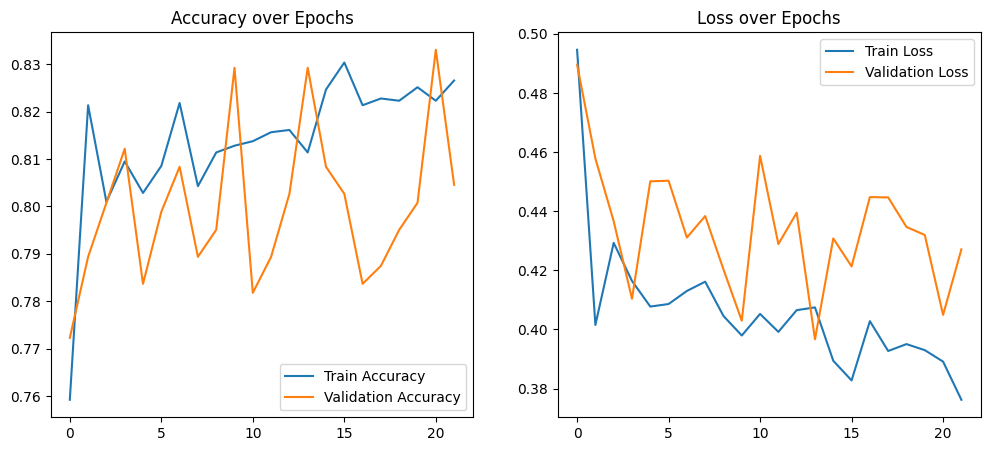

In [15]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_acc_hist, label='Train Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss_hist, label='Train Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


In [16]:
# Load best model for evaluation
model = models.mobilenet_v3_large(weights=None)
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, num_classes)
model.load_state_dict(torch.load('skin_lesions_model_mobilenetv3.pth'))
model = model.to(device)


In [17]:
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F

# Transform used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Class labels (must match training order)
class_names = ['benign', 'malignant']

def predict_image(image_path, model):
    image = Image.open(image_path).convert('RGB')
    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = F.softmax(output, dim=1)
        confidence, pred_idx = torch.max(probs, 1)

    predicted_label = class_names[pred_idx.item()]
    return predicted_label, confidence.item()


In [18]:
image_path = r"data\Skin Lesions Classification\test\malignant\3.jpg"
label, confidence = predict_image(image_path, model)
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


Prediction: malignant (56.42% confidence)


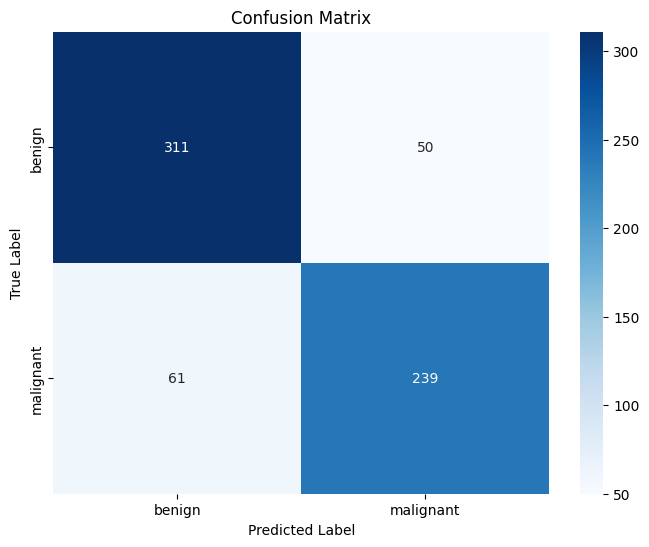

In [19]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [20]:
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      benign       0.84      0.86      0.85       361
   malignant       0.83      0.80      0.81       300

    accuracy                           0.83       661
   macro avg       0.83      0.83      0.83       661
weighted avg       0.83      0.83      0.83       661



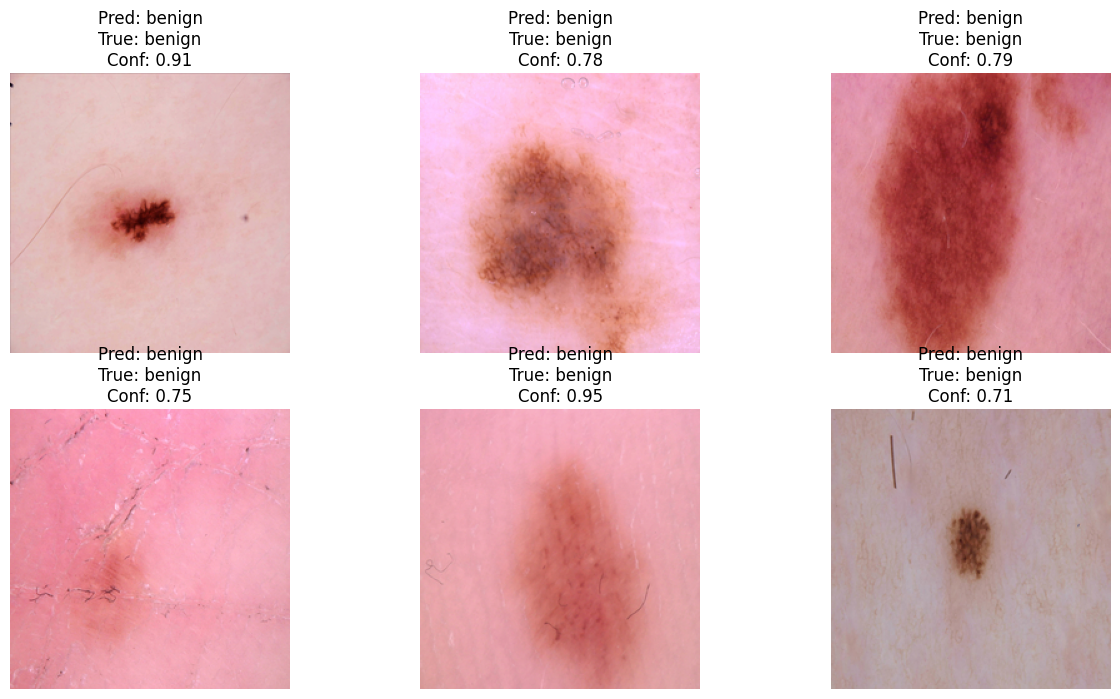

In [21]:
def visualize_predictions(model, data_loader, num_images=6):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 8))

    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)

            for i in range(imgs.size(0)):
                if images_shown == num_images:
                    return
                image = imgs[i].cpu().permute(1, 2, 0).numpy()
                image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
                image = np.clip(image, 0, 1)
                plt.subplot(2, 3, images_shown+1)
                plt.imshow(image)
                plt.axis('off')
                plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}\nConf: {probs[i][preds[i]]:.2f}")
                images_shown += 1

visualize_predictions(model, test_loader)


ROC-AUC: 0.2651
PR-AUC: 0.3248


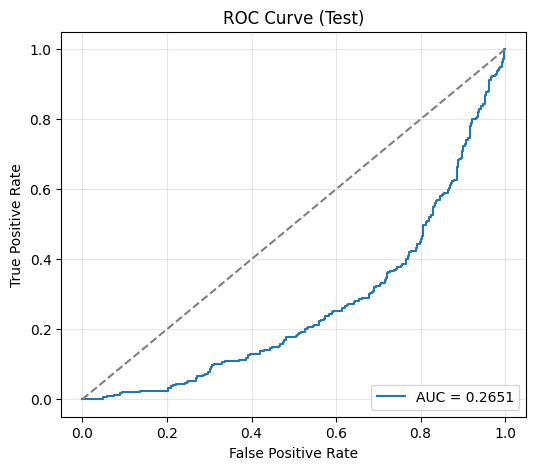

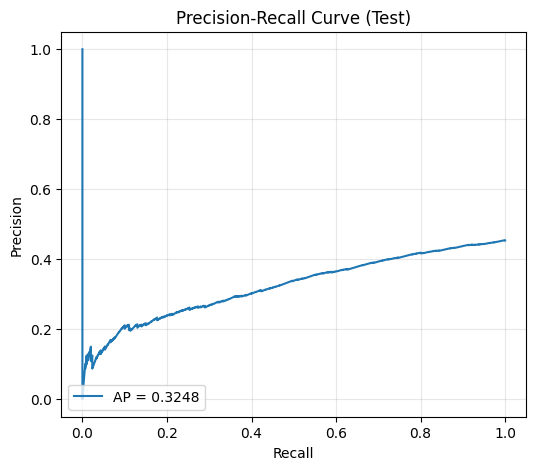

In [12]:
# --- ROC/PR AUC evaluation cell (auto-added) ---
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

missing = [name for name in ["model", "test_loader"] if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing) +
        ". Run the notebook setup/training/loading cells first, then run this AUC cell."
    )

model.eval()
y_true, y_prob_pos = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        logits = model(imgs)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.cpu().numpy().tolist())
        y_prob_pos.extend(probs[:, 1].cpu().numpy().tolist())

y_true = np.array(y_true)
y_prob_pos = np.array(y_prob_pos)

roc_auc = roc_auc_score(y_true, y_prob_pos)
pr_auc = average_precision_score(y_true, y_prob_pos)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

fpr, tpr, _ = roc_curve(y_true, y_prob_pos)
roc_curve_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_curve_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

precision, recall, _ = precision_recall_curve(y_true, y_prob_pos)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Test)")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()
